# **Arabic Readability Classification Using XGBoost**

## **Experiment Objective**

This experiment evaluates baseline and tuned XGBoost models for **19-, 5-, and 4-level Arabic readability classification** using the same BAREC data splits and TF-IDF representation as Linear SVM. **QWK is the hyperparameter-selection metric** because the readability labels are ordered [1].

## **Why XGBoost?**

XGBoost combines gradient-boosted decision trees to learn nonlinear patterns in numerical text features. It provides an alternative to Linear SVM while keeping the input representation consistent [2].

## **Experimental Protocol**

1. **Baseline:** fit on **Train**; report all evaluation metrics and the confusion matrix on **Dev**.
2. **GridSearchCV:** fit candidate models on **Train**, score each on the fixed **Dev** split using **Quadratic Weighted Kappa (QWK)**, and report the best parameters and best Dev QWK [5, 6].
3. **Tuned evaluation:** create fresh models using the selected hyperparameters, fit them on **Train** (with and without class weights), and calculate complete metrics on **Dev**. This is a separate fit; Dev is **not** used to train these models.
4. **Final Test:** only after choosing one task and one model variant using Dev results, optionally refit that selected configuration on **Train + Dev** and evaluate **Test once**. The Test set is not used for tuning or model selection.

**Terminology:** *Training based on Dev* means choosing settings using Dev performance, **not fitting the model to Dev labels** during development.


## **1. Data Loading**

Load the same prepared BAREC splits as Linear SVM. **Train** is used for fitting, **Dev** for comparison and QWK-based tuning, and **Test** is reserved for the final evaluation after model selection. The prepared files are used without additional preprocessing.


In [1]:

import os
import zipfile
import pandas as pd

# Define ZIP file path
zip_path = "/content/BAREC_prepared_datasets.zip"

# Load datasets directly from ZIP
with zipfile.ZipFile(zip_path, "r") as dataset_zip:
    zip_members = dataset_zip.namelist()

    def load_csv_from_zip(folder, split):
        expected_path = f"{folder}/{split}.csv"

        matches = [
            member for member in zip_members
            if member.replace("\\", "/").strip("/").endswith("/" + expected_path)
            or member.replace("\\", "/").strip("/") == expected_path
        ]

        if len(matches) != 1:
            raise FileNotFoundError(
                f"Expected {expected_path} inside ZIP, found {len(matches)}."
            )

        with dataset_zip.open(matches[0]) as csv_file:
            return pd.read_csv(csv_file)

    # Load original dataset splits
    train_original = load_csv_from_zip("original", "train")
    dev_original = load_csv_from_zip("original", "dev")
    test_original = load_csv_from_zip("original", "test")

    # Load four-level dataset splits
    train_4level = load_csv_from_zip("merged_4_level", "train")
    dev_4level = load_csv_from_zip("merged_4_level", "dev")
    test_4level = load_csv_from_zip("merged_4_level", "test")

# Inspect dataset structure
datasets = {
    "Original - Train": train_original,
    "Original - Dev": dev_original,
    "Original - Test": test_original,
    "Four-Level - Train": train_4level,
    "Four-Level - Dev": dev_4level,
    "Four-Level - Test": test_4level,
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(name)
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")



Original - Train
Shape: (54845, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Original - Dev
Shape: (7310, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Original - Test
Shape: (7286, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Four-Level - Train
Shape: (54845, 20)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 

In [3]:
# Select dataset versions
train_original = datasets["Original - Train"]
dev_original = datasets["Original - Dev"]
test_original = datasets["Original - Test"]

train_4level = datasets["Four-Level - Train"]
dev_4level = datasets["Four-Level - Dev"]
test_4level = datasets["Four-Level - Test"]

# Define input text
xgb_X_train = train_original["Word"]
xgb_X_dev = dev_original["Word"]
xgb_X_test = test_original["Word"]

# Readability labels available for each experimental setup
xgb_y_train_19_raw = train_original["Readability_Level_19"]
xgb_y_dev_19_raw = dev_original["Readability_Level_19"]
xgb_y_test_19_raw = test_original["Readability_Level_19"]

xgb_y_train_5_raw = train_original["Readability_Level_5"]
xgb_y_dev_5_raw = dev_original["Readability_Level_5"]
xgb_y_test_5_raw = test_original["Readability_Level_5"]

xgb_y_train_4_raw = train_4level["Readability_Level_4"]
xgb_y_dev_4_raw = dev_4level["Readability_Level_4"]
xgb_y_test_4_raw = test_4level["Readability_Level_4"]

print("Prepared data loaded. Original and four-level splits remain separate.")

Prepared data loaded. Original and four-level splits remain separate.


## **2. Feature Extraction Using TF-IDF**

The `Word` column is represented using `TfidfVectorizer(ngram_range=(1, 2))`, consistent with Linear SVM [4]. The vectorizer is **fitted on Train only** during development, then used to transform Dev and Test. Test features are not used for model fitting or selection.


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
xgb_vectorizer = TfidfVectorizer(ngram_range=(1, 2))

# Fit on training data and transform all splits
xgb_X_train_tfidf = xgb_vectorizer.fit_transform(xgb_X_train)
xgb_X_dev_tfidf = xgb_vectorizer.transform(xgb_X_dev)
xgb_X_test_tfidf = xgb_vectorizer.transform(xgb_X_test)

# Display feature matrix information
print("Training TF-IDF shape:", xgb_X_train_tfidf.shape)
print("Development TF-IDF shape:", xgb_X_dev_tfidf.shape)
print("Test TF-IDF shape:", xgb_X_test_tfidf.shape)
print("Vocabulary size:", len(xgb_vectorizer.vocabulary_))

Training TF-IDF shape: (54845, 520826)
Development TF-IDF shape: (7310, 520826)
Test TF-IDF shape: (7286, 520826)
Vocabulary size: 520826


### 2.1 Four-Level Data Alignment
the 4-level experiment **reuses the TF-IDF features fitted on the original training text**. Before reusing them, verify that the four-level files contain the same sentences in the same order; otherwise feature rows and class labels would not correspond.

In [5]:
# The 4-level procedure reuses the original TF-IDF matrices.
# Verify that the four-level labels align with those matrix rows.
for split_name, original_df, four_df in [
    ("Train", train_original, train_4level),
    ("Dev", dev_original, dev_4level),
    ("Test", test_original, test_4level),
]:
    aligned = original_df["Word"].reset_index(drop=True).equals(
        four_df["Word"].reset_index(drop=True)
    )
    print(f"{split_name}: original / four-level text rows aligned: {aligned}")
    if not aligned:
        raise ValueError(
            f"{split_name} text rows are not aligned. The SVM-style 4-level "
            "TF-IDF reuse would pair the wrong sentences with labels."
        )

# Reuse exactly the same features as the SVM 4-level experiment.
xgb_X_train_4_tfidf = xgb_X_train_tfidf
xgb_X_dev_4_tfidf = xgb_X_dev_tfidf
xgb_X_test_4_tfidf = xgb_X_test_tfidf

print("Four-level training TF-IDF shape:", xgb_X_train_4_tfidf.shape)
print("Four-level development TF-IDF shape:", xgb_X_dev_4_tfidf.shape)

Train: original / four-level text rows aligned: True
Dev: original / four-level text rows aligned: True
Test: original / four-level text rows aligned: True
Four-level training TF-IDF shape: (54845, 520826)
Four-level development TF-IDF shape: (7310, 520826)


## **3. Model Evaluation**

### 3.1 Evaluation Metrics Overview

**QWK** is the primary criterion for choosing hyperparameters because larger errors between ordered readability levels are penalized more strongly [1].

- **QWK:** Chance-adjusted ordinal agreement; higher is better.
- **Accuracy:** Exact-match proportion; higher is better.
- **Adjacent Accuracy (±1):** Predictions within one level; higher is better.
- **Macro F1:** Average across classes with equal class importance.
- **Weighted Precision / Recall:** Averages weighted by class support.
- **MAE / RMSE:** Magnitude of numerical label errors; lower is better.
- **R²:** Auxiliary numerical diagnostic, not the model-selection criterion.
- **Confusion Matrix:** Displays per-class prediction errors.

Metrics are reported on **original 1-based readability labels**, not the internal 0-based XGBoost labels.


### 3.2 Evaluation Function

The reusable function prints all metrics and a per-class classification report.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    mean_absolute_error,
    mean_squared_error,
    classification_report,
    cohen_kappa_score,
    r2_score,
    confusion_matrix
)


def evaluate_xgb_model(y_true, y_pred, dataset_name):
    """Evaluate XGBoost using exactly the SVM evaluation metrics."""
    accuracy = accuracy_score(y_true, y_pred)
    adj_accuracy = np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= 1)
    qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print("=" * 60)
    print(dataset_name)
    print("=" * 60)
    print(f"Accuracy:                      {accuracy:.4f}")
    print(f"Adjacent Accuracy (±1):        {adj_accuracy:.4f}")
    print(f"Quadratic Weighted Kappa:      {qwk:.4f}")
    print(f"Macro F1-score:                {macro_f1:.4f}")
    print(f"Weighted Precision:            {precision:.4f}")
    print(f"Weighted Recall:               {recall:.4f}")
    print(f"Mean Absolute Error (MAE):     {mae:.4f}")
    print(f"Root Mean Squared Error:       {rmse:.4f}")
    print(f"R² Score:                      {r2:.4f}")

    print("\nClassification Report:\n")
    print(classification_report(y_true, y_pred, zero_division=0))

### 3.3 Confusion Matrix Visualization

A reusable confusion matrix function is implemented to visualize classification performance and identify common misclassification patterns between readability levels.

In [7]:
def plot_confusion_matrix(y_true, y_pred, labels, title):
    """Plot a confusion matrix for a classification model."""

    cm = confusion_matrix(y_true, y_pred, labels=labels)

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

## **4. XGBoost (19-Level)**

### 4.1 XGBoost Baseline (19-Level)

Fit a baseline XGBoost classifier using **Train** and evaluate its predictions on **Dev**. Report QWK together with the remaining metrics and confusion matrix. The Dev labels are used **only for evaluation**, not for fitting. The baseline provides the reference for the tuned models [3].


In [8]:
# Install and import XGBoost
!pip install xgboost -q

import xgboost as xgb
print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


Original label range: 1 to 19
Encoded label range: 0 to 18
{'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': None, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}
Baseline XGBoost (19

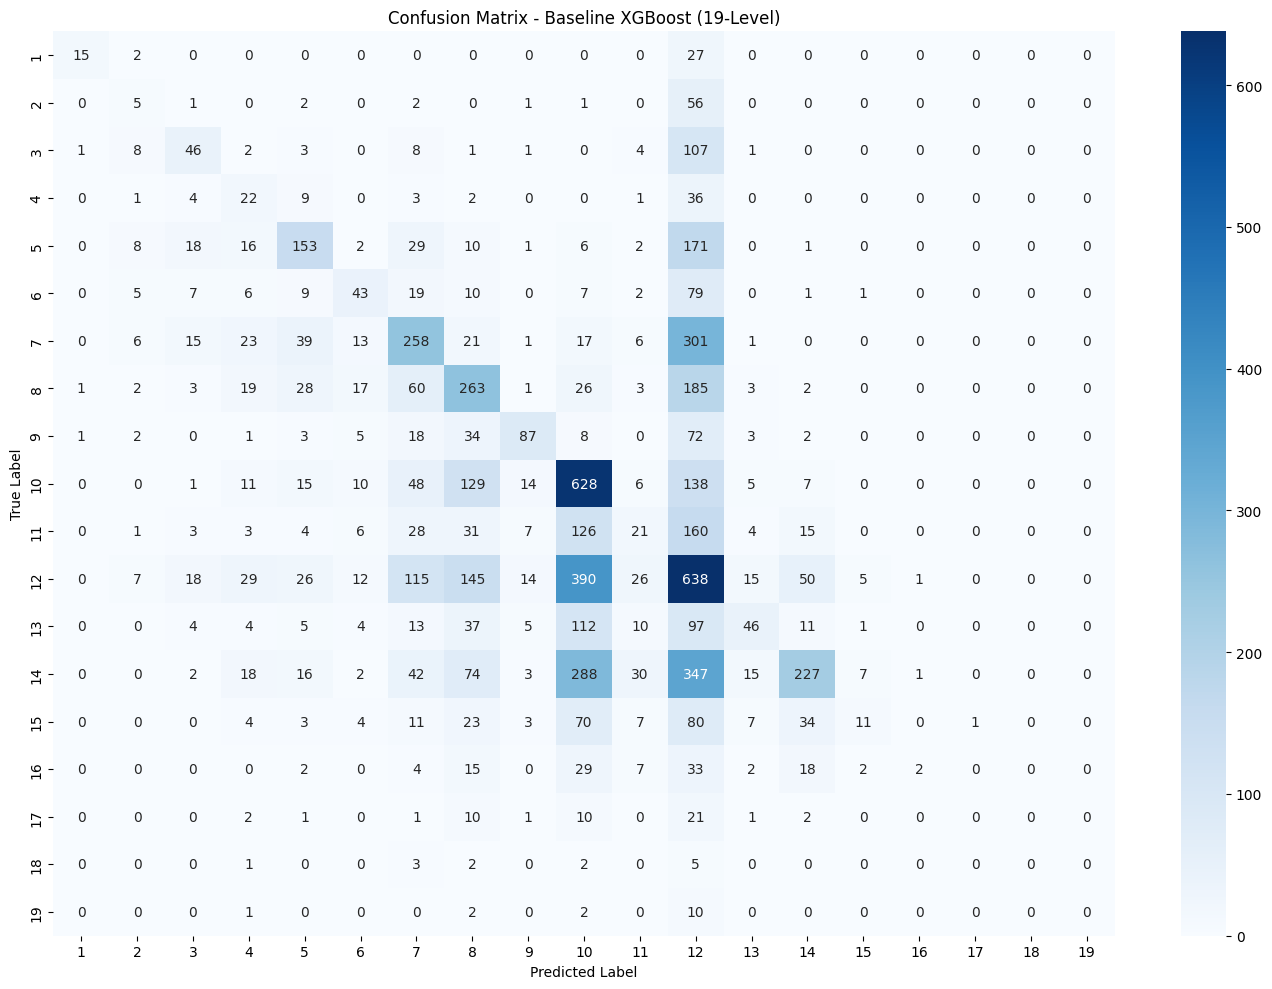

In [9]:
# XGBoost's multiclass objectives (multi:softmax / multi:softprob) require
# integer class labels in the range [0, num_class - 1].
# This is a documented library requirement (automatic label encoding was
# removed from XGBClassifier starting from version 1.6), NOT a modeling choice.
from sklearn.preprocessing import LabelEncoder

xgb_label_encoder = LabelEncoder()

xgb_y_train_19 = xgb_label_encoder.fit_transform(train_original["Readability_Level_19"])
xgb_y_dev_19 = xgb_label_encoder.transform(dev_original["Readability_Level_19"])
xgb_y_test_19 = xgb_label_encoder.transform(test_original["Readability_Level_19"])

print("Original label range:", train_original["Readability_Level_19"].min(),
      "to", train_original["Readability_Level_19"].max())
print("Encoded label range:", xgb_y_train_19.min(), "to", xgb_y_train_19.max())

from xgboost import XGBClassifier

# Baseline XGBoost model using library default hyperparameters.
# objective is set explicitly to multi:softprob because this is dictated by
# the task (multiclass with 19 classes), not an arbitrary choice —
# the model predicts class labels with predict() and can output class probabilities with predict_proba().
xgb_baseline_19 = XGBClassifier(
    objective="multi:softprob",
    random_state=42   # shared project-level value, consistent with RF/SVM
)

print(xgb_baseline_19.get_params())

# Train the baseline model
xgb_baseline_19.fit(
    xgb_X_train_tfidf,
    xgb_y_train_19
)

# Generate predictions using the baseline xgb model
xgb_baseline_19_dev_pred = xgb_baseline_19.predict(xgb_X_dev_tfidf)

evaluate_xgb_model(
    xgb_label_encoder.inverse_transform(xgb_y_dev_19),
    xgb_label_encoder.inverse_transform(xgb_baseline_19_dev_pred),
    "Baseline XGBoost (19-Level) - Dev Set"
)

plot_confusion_matrix(
    xgb_label_encoder.inverse_transform(xgb_y_dev_19),
    xgb_label_encoder.inverse_transform(xgb_baseline_19_dev_pred),
    labels=list(range(1, 20)),
    title="Confusion Matrix - Baseline XGBoost (19-Level)"
)

### 4.2 XGBoost Baseline Findings (19-Level)

The baseline XGBoost achieved 0.3372 Accuracy and 0.2988 QWK on the development set. Adjacent Accuracy was 0.4360, with a Macro F1-score of 0.2341.

The model struggled with higher readability levels, failing to correctly classify samples from Levels 17–19. The low QWK and Macro F1-score indicate limited performance in capturing ordinal relationships and distinguishing between readability levels. These results establish a baseline for subsequent hyperparameter tuning.

### 4.3 XGBoost Hyperparameter Tuning Using GridSearchCV (19-Level)

`GridSearchCV` selects the `n_estimators` value that produces the **highest Dev QWK**, using a fixed Train/Dev split (`PredefinedSplit`). All candidates are **trained on Train**, evaluated on **Dev**, and **never evaluated on Test** during tuning [5, 6].

**Hyperparameters and Justification**

| Parameter | Setting | Justification |
|---|---|---|
| `n_estimators` | `[100, 200, 300]` (searched) | Tests three tree counts to assess boosting complexity; this is an experimental search range, not a published BAREC optimum [2, 3]. |
| `learning_rate` | `0.3` (fixed) | XGBoost's documented tree-booster default; kept fixed to isolate the effect of tree count [3]. |
| `max_depth` | `6` (fixed) | XGBoost's documented default depth, controlling the complexity of individual trees [3]. |
| Selection metric | **QWK** | Accounts for ordered readability levels and penalizes larger disagreements [1]. |

**Output:** best `n_estimators` and **best Dev QWK**. Class weighting is compared **after** this unweighted search; the chosen tree count is not separately optimized for the balanced variant.


In [11]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import make_scorer, cohen_kappa_score

# Quadratic weighting respects the order of readability levels.
# The 0-based encoded labels preserve the original class spacing.
xgb_qwk_scorer = make_scorer(cohen_kappa_score, weights="quadratic")
from xgboost import XGBClassifier
from scipy.sparse import vstack
import numpy as np
import time

# learning_rate is fixed at 0.3 (XGBoost tree-booster default);
# this notebook does not tune learning_rate.
xgb_param_grid = {
    "n_estimators": [100, 200, 300]
}

FIXED_LEARNING_RATE = 0.3

# Stack the existing TF-IDF matrices for PredefinedSplit; no new feature fitting
xgb_X_train_dev = vstack([
    xgb_X_train_tfidf,
    xgb_X_dev_tfidf
])
xgb_y_train_dev = np.concatenate([xgb_y_train_19, xgb_y_dev_19])

test_fold = np.concatenate([
    np.full(len(xgb_y_train_19), -1),
    np.zeros(len(xgb_y_dev_19))
])
predefined_split = PredefinedSplit(test_fold=test_fold)

# ---- Optional single-fit timing check before the full grid ----
_t0 = time.time()
_probe = XGBClassifier(
    n_estimators=300, learning_rate=FIXED_LEARNING_RATE, max_depth=6,
    objective="multi:softprob", tree_method="hist",
    device="cuda",
    random_state=42
)
_probe.fit(xgb_X_train_tfidf, xgb_y_train_19)
_single = time.time() - _t0
print(f"Single fit (worst case, GPU) took {_single:.1f} sec")
print(f"Estimated total grid time (3 combos): ~{(_single*3)/3600:.2f} hours")

# ---- Search on Dev QWK; no class weighting during selection ----
xgb_grid_19 = GridSearchCV(
    estimator=XGBClassifier(
        objective="multi:softprob",
        learning_rate=FIXED_LEARNING_RATE,
        random_state=42,
        max_depth=6,
        tree_method="hist",
        device="cuda"
    ),
    param_grid=xgb_param_grid,
    scoring=xgb_qwk_scorer,
    cv=predefined_split,
    refit=False,  # do not train GridSearchCV best estimator on Train + Dev
    n_jobs=1,
    verbose=2
)

xgb_grid_19.fit(xgb_X_train_dev, xgb_y_train_dev)

print("Best Parameters:", xgb_grid_19.best_params_)
print(f"Best Development QWK: {xgb_grid_19.best_score_:.4f}")

Single fit (worst case, GPU) took 557.3 sec
Estimated total grid time (3 combos): ~0.46 hours
Fitting 1 folds for each of 3 candidates, totalling 3 fits


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [12:31:53] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


[CV] END ...................................n_estimators=100; total time= 3.6min
[CV] END ...................................n_estimators=200; total time= 6.5min
[CV] END ...................................n_estimators=300; total time= 9.4min
Best Parameters: {'n_estimators': 300}
Best Development QWK: 0.3665


### 4.4 Tuned XGBoost — Balanced (19-Level)

**Retrain on Train** with GridSearchCV's QWK-selected tree count and balanced `sample_weight` computed from **Train labels only** [7]. Then compute **all metrics and the confusion matrix on Dev**. No Dev samples are used for fitting.


Tuned XGBoost (19-Level) - Balanced - Dev Set
Accuracy:                      0.2996
Adjacent Accuracy (±1):        0.4126
Quadratic Weighted Kappa:      0.4285
Macro F1-score:                0.2350
Weighted Precision:            0.3800
Weighted Recall:               0.2996
Mean Absolute Error (MAE):     2.8337
Root Mean Squared Error:       4.0697
R² Score:                      -0.4570

Classification Report:

              precision    recall  f1-score   support

           1       0.70      0.68      0.69        44
           2       0.18      0.21      0.19        68
           3       0.15      0.80      0.25       182
           4       0.06      0.44      0.11        78
           5       0.38      0.42      0.40       417
           6       0.22      0.39      0.28       189
           7       0.34      0.39      0.36       701
           8       0.27      0.44      0.34       613
           9       0.39      0.38      0.38       236
          10       0.38      0.57      0.45  

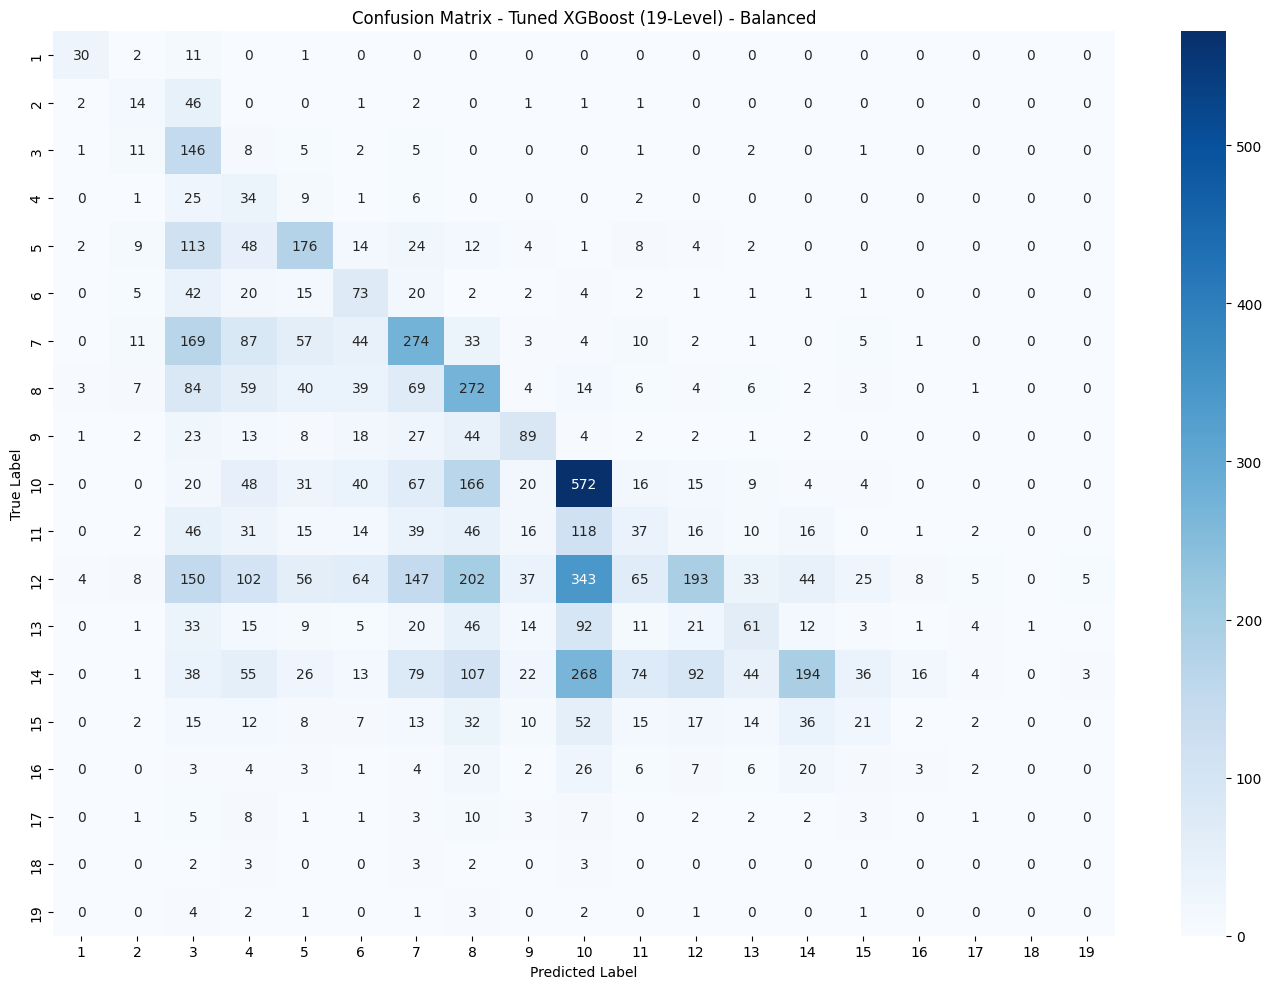

In [12]:
from sklearn.utils.class_weight import compute_sample_weight

xgb_sample_weights_balanced = compute_sample_weight(class_weight="balanced", y=xgb_y_train_19)

# Create tuned XGBoost using the best n_estimators/learning_rate with balanced sample weights
xgb_tuned_19_balanced = XGBClassifier(
    n_estimators=xgb_grid_19.best_params_["n_estimators"],
    learning_rate=FIXED_LEARNING_RATE,
    max_depth=6,
    objective="multi:softprob",
    tree_method="hist",
    device="cuda",
    random_state=42
)

# Fresh fit on Train; evaluate predictions on Dev only
xgb_tuned_19_balanced.fit(
    xgb_X_train_tfidf,
    xgb_y_train_19,
    sample_weight=xgb_sample_weights_balanced
)

# Predict the held-out Dev set for complete evaluation
xgb_tuned_19_balanced_dev_pred = xgb_tuned_19_balanced.predict(xgb_X_dev_tfidf)

evaluate_xgb_model(
    xgb_label_encoder.inverse_transform(xgb_y_dev_19),
    xgb_label_encoder.inverse_transform(xgb_tuned_19_balanced_dev_pred),
    "Tuned XGBoost (19-Level) - Balanced - Dev Set"
)

plot_confusion_matrix(
    xgb_label_encoder.inverse_transform(xgb_y_dev_19),
    xgb_label_encoder.inverse_transform(xgb_tuned_19_balanced_dev_pred),
    labels=list(range(1, 20)),
    title="Confusion Matrix - Tuned XGBoost (19-Level) - Balanced"
)

### 4.5 Tuned XGBoost — No Class Weighting (19-Level)

**Retrain on Train** using the same QWK-selected hyperparameters but without sample weights. Evaluate **all metrics and the confusion matrix on Dev**. This comparison isolates the effect of class balancing at a fixed tree count.


Tuned XGBoost (19-Level) - None - Dev Set
Accuracy:                      0.3543
Adjacent Accuracy (±1):        0.4592
Quadratic Weighted Kappa:      0.3665
Macro F1-score:                0.2446
Weighted Precision:            0.3767
Weighted Recall:               0.3543
Mean Absolute Error (MAE):     2.4124
Root Mean Squared Error:       3.5772
R² Score:                      -0.1257

Classification Report:

              precision    recall  f1-score   support

           1       0.79      0.34      0.48        44
           2       0.13      0.09      0.11        68
           3       0.32      0.33      0.32       182
           4       0.12      0.29      0.17        78
           5       0.43      0.43      0.43       417
           6       0.35      0.31      0.32       189
           7       0.40      0.46      0.43       701
           8       0.31      0.47      0.38       613
           9       0.60      0.36      0.45       236
          10       0.37      0.64      0.47      

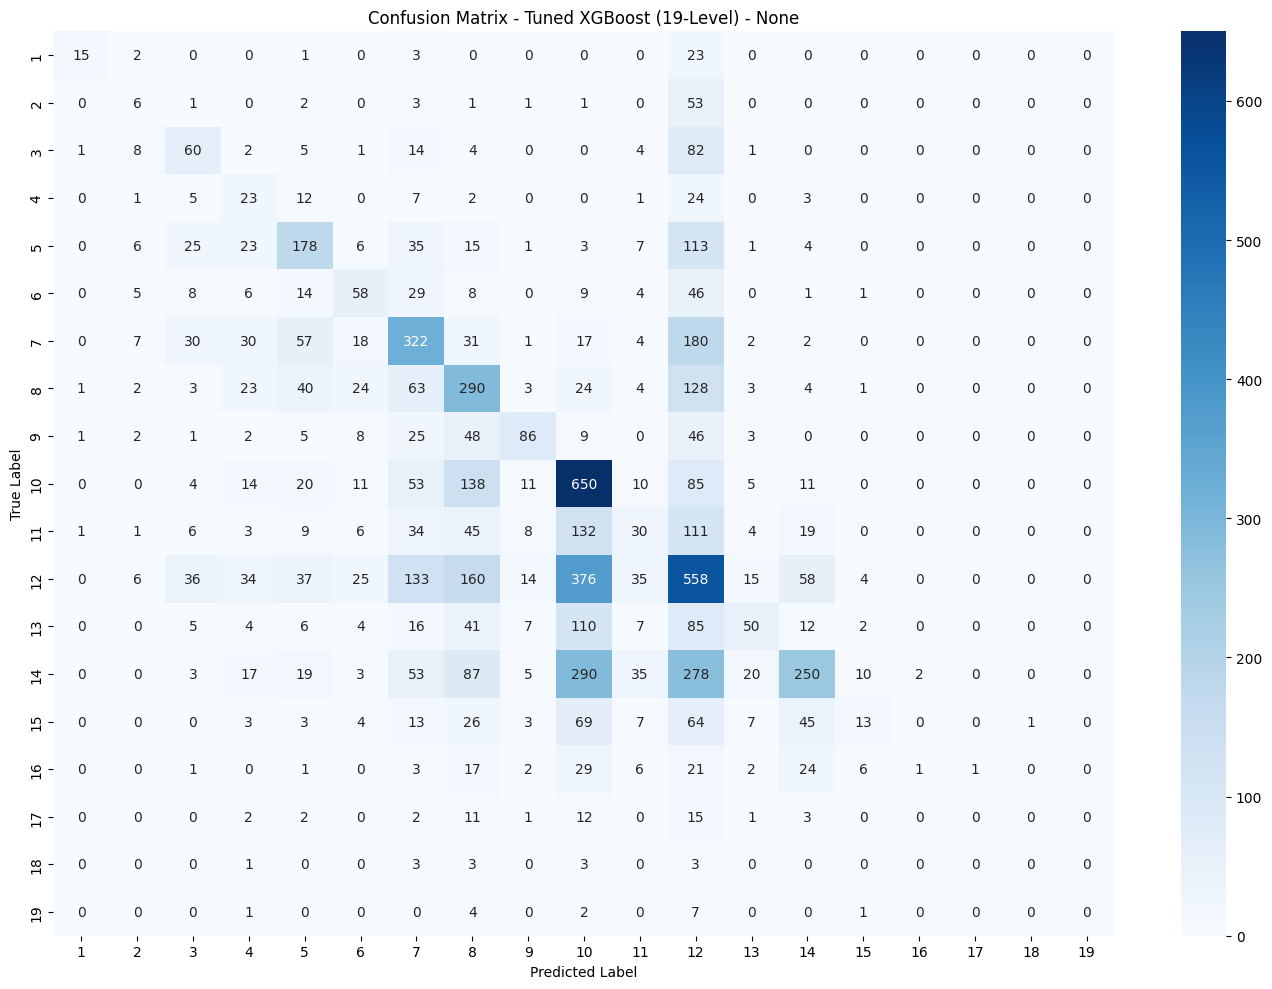

In [13]:
# Use the n_estimators value selected by Dev QWK (without weighting)
xgb_tuned_19_none = XGBClassifier(
    n_estimators=xgb_grid_19.best_params_["n_estimators"],
    learning_rate=FIXED_LEARNING_RATE,
    max_depth=6,
    objective="multi:softprob",
    tree_method="hist",
    device="cuda",
    random_state=42
)

# Fresh fit on Train; evaluate predictions on Dev only
xgb_tuned_19_none.fit(
    xgb_X_train_tfidf,
    xgb_y_train_19
)

# Predict the held-out Dev set for complete evaluation
xgb_tuned_19_none_dev_pred = xgb_tuned_19_none.predict(xgb_X_dev_tfidf)

evaluate_xgb_model(
    xgb_label_encoder.inverse_transform(xgb_y_dev_19),
    xgb_label_encoder.inverse_transform(xgb_tuned_19_none_dev_pred),
    "Tuned XGBoost (19-Level) - None - Dev Set"
)

plot_confusion_matrix(
    xgb_label_encoder.inverse_transform(xgb_y_dev_19),
    xgb_label_encoder.inverse_transform(xgb_tuned_19_none_dev_pred),
    labels=list(range(1, 20)),
    title="Confusion Matrix - Tuned XGBoost (19-Level) - None"
)

### 4.6 Tuned XGBoost Findings (19-Level)

GridSearchCV selected n_estimators = 300, achieving a best Dev QWK of 0.3665.

The tuned unbalanced model achieved the highest Accuracy (0.3543) and lowest MAE (2.4124), improving over the baseline. The balanced model achieved a higher QWK (0.4285 vs. 0.3665) but lower Accuracy (0.2996) and higher MAE (2.8337).

The confusion matrices show that both models struggled with higher readability levels, particularly Levels 17–19.

Overall, class balancing improved ordinal agreement but reduced exact classification accuracy and increased prediction errors

## **5. XGBoost (5-Level)**

### 5.1 XGBoost Baseline (5-Level)

Fit a baseline XGBoost classifier using **Train** and evaluate its predictions on **Dev**. Report QWK together with the remaining metrics and confusion matrix. The Dev labels are used **only for evaluation**, not for fitting. The baseline provides the reference for the tuned models [3].


Encoded label range: 0 to 4
{'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': None, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}
Baseline XGBoost (5-Level) - Dev Set
Accuracy:     

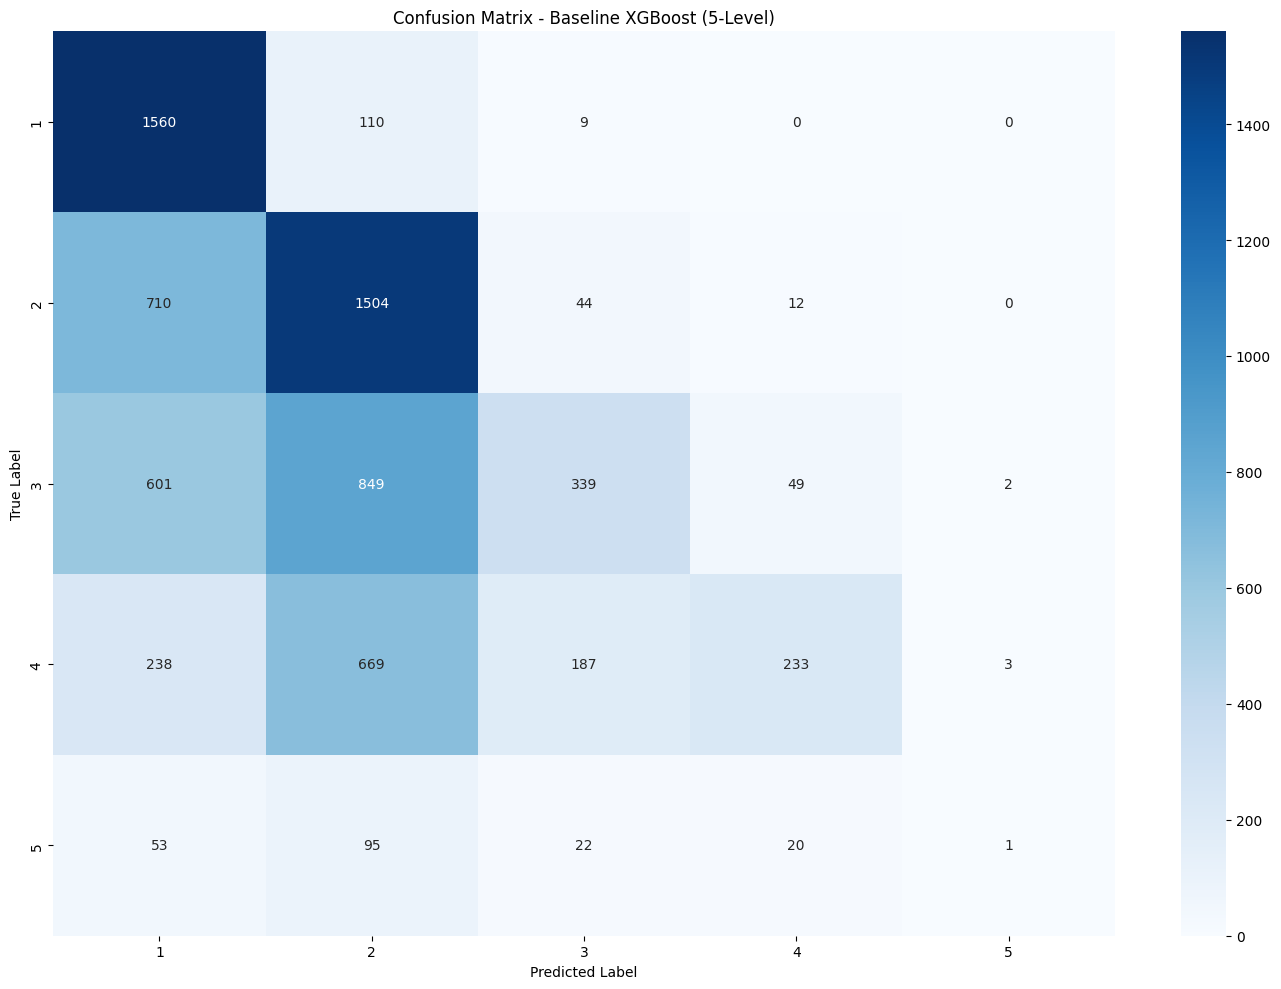

In [14]:
# Define target labels for the 5-level classification task
xgb_y_train_5_raw = train_original["Readability_Level_5"]
xgb_y_dev_5_raw = dev_original["Readability_Level_5"]
xgb_y_test_5_raw = test_original["Readability_Level_5"]

# Separate LabelEncoder for the 5-level task (independent from the 19-level encoder)
# Required because XGBoost's multiclass objective needs labels in [0, num_class-1]
from sklearn.preprocessing import LabelEncoder

xgb_label_encoder_5 = LabelEncoder()
xgb_y_train_5 = xgb_label_encoder_5.fit_transform(xgb_y_train_5_raw)
xgb_y_dev_5   = xgb_label_encoder_5.transform(xgb_y_dev_5_raw)
xgb_y_test_5  = xgb_label_encoder_5.transform(xgb_y_test_5_raw)

print("Encoded label range:", xgb_y_train_5.min(), "to", xgb_y_train_5.max())

from xgboost import XGBClassifier

# Baseline XGBoost model using library default hyperparameters (matches 19-level baseline)
xgb_baseline_5 = XGBClassifier(
    objective="multi:softprob",
    random_state=42
)

print(xgb_baseline_5.get_params())

xgb_baseline_5.fit(
    xgb_X_train_tfidf,
    xgb_y_train_5
)

xgb_baseline_5_dev_pred = xgb_baseline_5.predict(xgb_X_dev_tfidf)

evaluate_xgb_model(
    xgb_label_encoder_5.inverse_transform(xgb_y_dev_5),
    xgb_label_encoder_5.inverse_transform(xgb_baseline_5_dev_pred),
    "Baseline XGBoost (5-Level) - Dev Set"
)

plot_confusion_matrix(
    xgb_label_encoder_5.inverse_transform(xgb_y_dev_5),
    xgb_label_encoder_5.inverse_transform(xgb_baseline_5_dev_pred),
    labels=list(range(1, 6)),
    title="Confusion Matrix - Baseline XGBoost (5-Level)"
)

### 5.3 XGBoost Hyperparameter Tuning Using GridSearchCV (5-Level)

`GridSearchCV` selects the `n_estimators` value that produces the **highest Dev QWK**, using a fixed Train/Dev split (`PredefinedSplit`). All candidates are **trained on Train**, evaluated on **Dev**, and **never evaluated on Test** during tuning [5, 6].

**Hyperparameters and Justification**

| Parameter | Setting | Justification |
|---|---|---|
| `n_estimators` | `[100, 200, 300]` (searched) | Tests three tree counts to assess boosting complexity; this is an experimental search range, not a published BAREC optimum [2, 3]. |
| `learning_rate` | `0.3` (fixed) | XGBoost's documented tree-booster default; kept fixed to isolate the effect of tree count [3]. |
| `max_depth` | `6` (fixed) | XGBoost's documented default depth, controlling the complexity of individual trees [3]. |
| Selection metric | **QWK** | Accounts for ordered readability levels and penalizes larger disagreements [1]. |

**Output:** best `n_estimators` and **best Dev QWK**. Class weighting is compared **after** this unweighted search; the chosen tree count is not separately optimized for the balanced variant.


In [15]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import make_scorer, cohen_kappa_score

# Quadratic weighting respects the order of readability levels.
# The 0-based encoded labels preserve the original class spacing.
xgb_qwk_scorer = make_scorer(cohen_kappa_score, weights="quadratic")
from xgboost import XGBClassifier
from scipy.sparse import vstack
import numpy as np

xgb_param_grid_5 = {
    "n_estimators": [100, 200, 300]
}

FIXED_LEARNING_RATE = 0.3   # same fixed value as 19-level, for consistency

# Stack Train and Dev for the fixed CV indices; only Train is fitted per fold
xgb_X_train_dev_5 = vstack([
    xgb_X_train_tfidf,
    xgb_X_dev_tfidf
])

xgb_y_train_dev_5 = np.concatenate([
    xgb_y_train_5,
    xgb_y_dev_5
])

# Define the fixed split
# -1 = rows used for fitting (Train)
#  0 = rows held out for scoring (Dev)
test_fold_5 = np.concatenate([
    np.full(len(xgb_y_train_5), -1),
    np.zeros(len(xgb_y_dev_5))
])
predefined_split_5 = PredefinedSplit(test_fold=test_fold_5)

# Grid Search uses the same predefined Dev split and QWK scorer
xgb_grid_5 = GridSearchCV(
    estimator=XGBClassifier(
        objective="multi:softprob",
        learning_rate=FIXED_LEARNING_RATE,
        random_state=42,
        max_depth=6,
        tree_method="hist",
        device="cuda"
    ),
    param_grid=xgb_param_grid_5,
    scoring=xgb_qwk_scorer,
    cv=predefined_split_5,
    refit=False,  # keep Dev held out for separate tuned evaluation
    n_jobs=1,
    verbose=2
)

xgb_grid_5.fit(
    xgb_X_train_dev_5,
    xgb_y_train_dev_5
)

print("Best Parameters:", xgb_grid_5.best_params_)
print(f"Best Development QWK: {xgb_grid_5.best_score_:.4f}")

Fitting 1 folds for each of 3 candidates, totalling 3 fits
[CV] END ...................................n_estimators=100; total time= 1.4min
[CV] END ...................................n_estimators=200; total time= 2.4min
[CV] END ...................................n_estimators=300; total time= 3.3min
Best Parameters: {'n_estimators': 300}
Best Development QWK: 0.3994


### 5.4 Tuned XGBoost — Balanced (5-Level)

**Retrain on Train** with GridSearchCV's QWK-selected tree count and balanced `sample_weight` computed from **Train labels only** [7]. Then compute **all metrics and the confusion matrix on Dev**. No Dev samples are used for fitting.


Tuned XGBoost (5-Level) - Balanced - Dev Set
Accuracy:                      0.5057
Adjacent Accuracy (±1):        0.7791
Quadratic Weighted Kappa:      0.4174
Macro F1-score:                0.3904
Weighted Precision:            0.5344
Weighted Recall:               0.5057
Mean Absolute Error (MAE):     0.7795
Root Mean Squared Error:       1.2229
R² Score:                      -0.2171

Classification Report:

              precision    recall  f1-score   support

           1       0.47      0.95      0.63      1679
           2       0.51      0.60      0.55      2270
           3       0.55      0.19      0.28      1840
           4       0.69      0.28      0.40      1330
           5       0.15      0.06      0.09       191

    accuracy                           0.51      7310
   macro avg       0.47      0.42      0.39      7310
weighted avg       0.53      0.51      0.46      7310



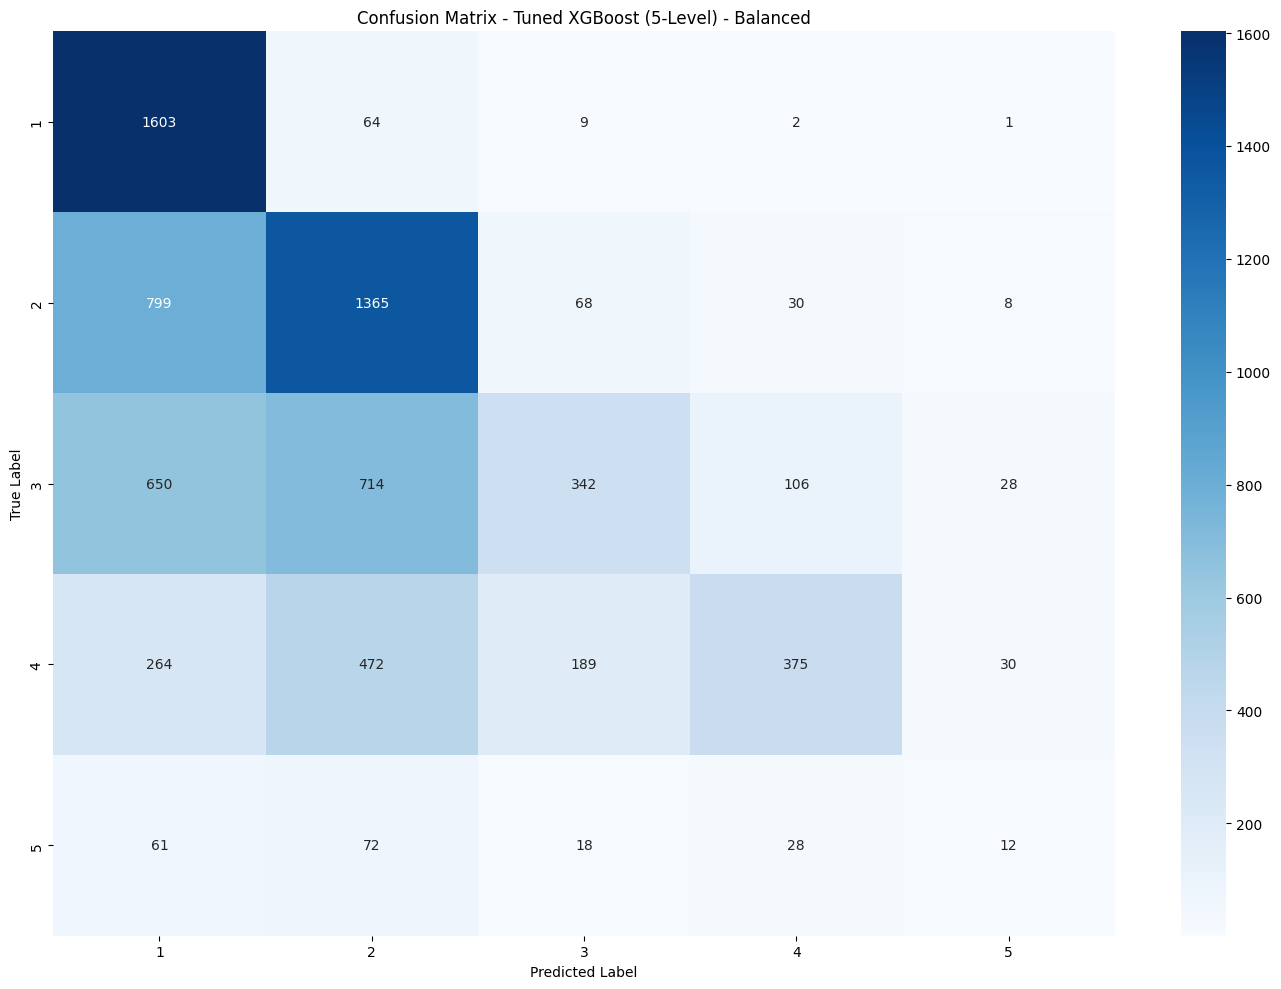

In [16]:
from sklearn.utils.class_weight import compute_sample_weight

xgb_sample_weights_balanced_5 = compute_sample_weight(class_weight="balanced", y=xgb_y_train_5)

# Create tuned XGBoost using the best n_estimators with balanced sample weights
xgb_tuned_5_balanced = XGBClassifier(
    n_estimators=xgb_grid_5.best_params_["n_estimators"],
    learning_rate=FIXED_LEARNING_RATE,
    max_depth=6,
    objective="multi:softprob",
    tree_method="hist",
    device="cuda",
    random_state=42
)

# Fresh fit on Train; evaluate predictions on Dev only
xgb_tuned_5_balanced.fit(
    xgb_X_train_tfidf,
    xgb_y_train_5,
    sample_weight=xgb_sample_weights_balanced_5
)

# Predict the held-out Dev set for complete evaluation
xgb_tuned_5_balanced_dev_pred = xgb_tuned_5_balanced.predict(xgb_X_dev_tfidf)

evaluate_xgb_model(
    xgb_label_encoder_5.inverse_transform(xgb_y_dev_5),
    xgb_label_encoder_5.inverse_transform(xgb_tuned_5_balanced_dev_pred),
    "Tuned XGBoost (5-Level) - Balanced - Dev Set"
)

plot_confusion_matrix(
    xgb_label_encoder_5.inverse_transform(xgb_y_dev_5),
    xgb_label_encoder_5.inverse_transform(xgb_tuned_5_balanced_dev_pred),
    labels=list(range(1, 6)),
    title="Confusion Matrix - Tuned XGBoost (5-Level) - Balanced"
)

### 5.5 Tuned XGBoost — No Class Weighting (5-Level)

**Retrain on Train** using the same QWK-selected hyperparameters but without sample weights. Evaluate **all metrics and the confusion matrix on Dev**. This comparison isolates the effect of class balancing at a fixed tree count.


Tuned XGBoost (5-Level) - None - Dev Set
Accuracy:                      0.5160
Adjacent Accuracy (±1):        0.7858
Quadratic Weighted Kappa:      0.3994
Macro F1-score:                0.3740
Weighted Precision:            0.5418
Weighted Recall:               0.5160
Mean Absolute Error (MAE):     0.7536
Root Mean Squared Error:       1.1909
R² Score:                      -0.1542

Classification Report:

              precision    recall  f1-score   support

           1       0.52      0.92      0.66      1679
           2       0.48      0.69      0.57      2270
           3       0.55      0.21      0.31      1840
           4       0.72      0.21      0.32      1330
           5       0.09      0.01      0.01       191

    accuracy                           0.52      7310
   macro avg       0.47      0.41      0.37      7310
weighted avg       0.54      0.52      0.46      7310



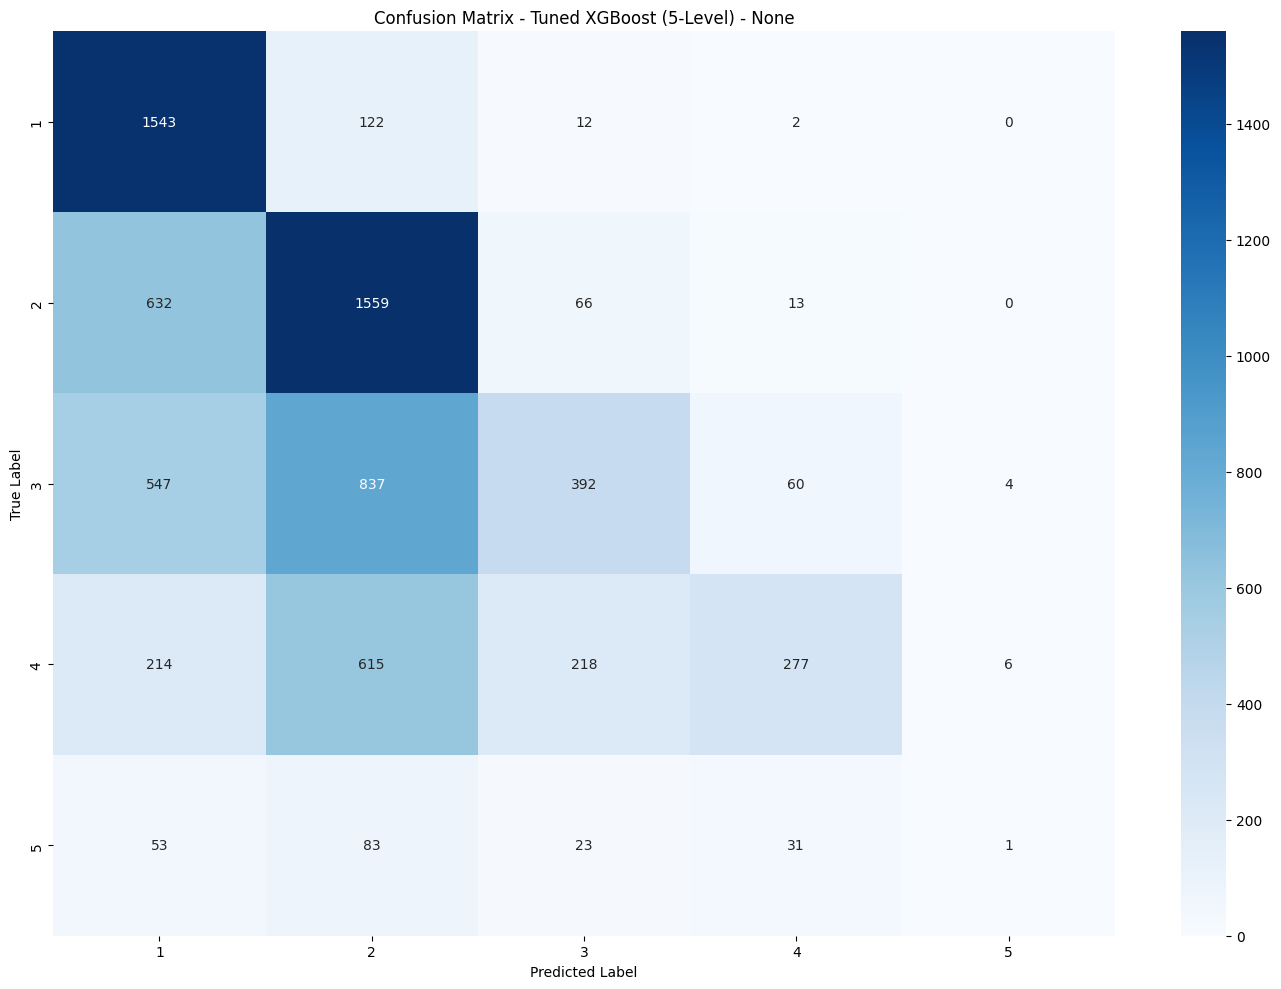

In [17]:
# Use the n_estimators value selected by Dev QWK (without weighting)
xgb_tuned_5_none = XGBClassifier(
    n_estimators=xgb_grid_5.best_params_["n_estimators"],
    learning_rate=FIXED_LEARNING_RATE,
    max_depth=6,
    objective="multi:softprob",
    tree_method="hist",
    device="cuda",
    random_state=42
)

# Fresh fit on Train; evaluate predictions on Dev only
xgb_tuned_5_none.fit(
    xgb_X_train_tfidf,
    xgb_y_train_5
)

# Predict the held-out Dev set for complete evaluation
xgb_tuned_5_none_dev_pred = xgb_tuned_5_none.predict(xgb_X_dev_tfidf)

evaluate_xgb_model(
    xgb_label_encoder_5.inverse_transform(xgb_y_dev_5),
    xgb_label_encoder_5.inverse_transform(xgb_tuned_5_none_dev_pred),
    "Tuned XGBoost (5-Level) - None - Dev Set"
)

plot_confusion_matrix(
    xgb_label_encoder_5.inverse_transform(xgb_y_dev_5),
    xgb_label_encoder_5.inverse_transform(xgb_tuned_5_none_dev_pred),
    labels=list(range(1, 6)),
    title="Confusion Matrix - Tuned XGBoost (5-Level) - None"
)

### 5.6 Tuned XGBoost Findings (5-Level)

The tuned unbalanced model achieved the highest Accuracy (0.5160), Adjacent Accuracy (0.7858), and lowest MAE (0.7536). The balanced model achieved higher QWK (0.4174 vs. 0.3994) and Macro F1-score (0.3904 vs. 0.3740).

The confusion matrices show that both models continued to struggle with Level 5, although balancing improved its recall from 0.01 to 0.06.

Overall, tuning improved performance over the baseline, while class balancing further improved ordinal agreement and Macro F1-score at a small cost to Accuracy.

## **6. XGBoost (4-Level)**

This experiment follows the SVM four-level dataset and reuses the original TF-IDF matrices **only after confirming exact row alignment**. The model itself remains XGBoost.

### 6.1 XGBoost Baseline (4-Level)

Fit a baseline XGBoost classifier using **Train** and evaluate its predictions on **Dev**. Report QWK together with the remaining metrics and confusion matrix. The Dev labels are used **only for evaluation**, not for fitting. The baseline provides the reference for the tuned models [3].


Encoded four-level classes: [1 2 3 4]
Encoded label range: 0 to 3
{'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': None, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}
Baseline XGBo

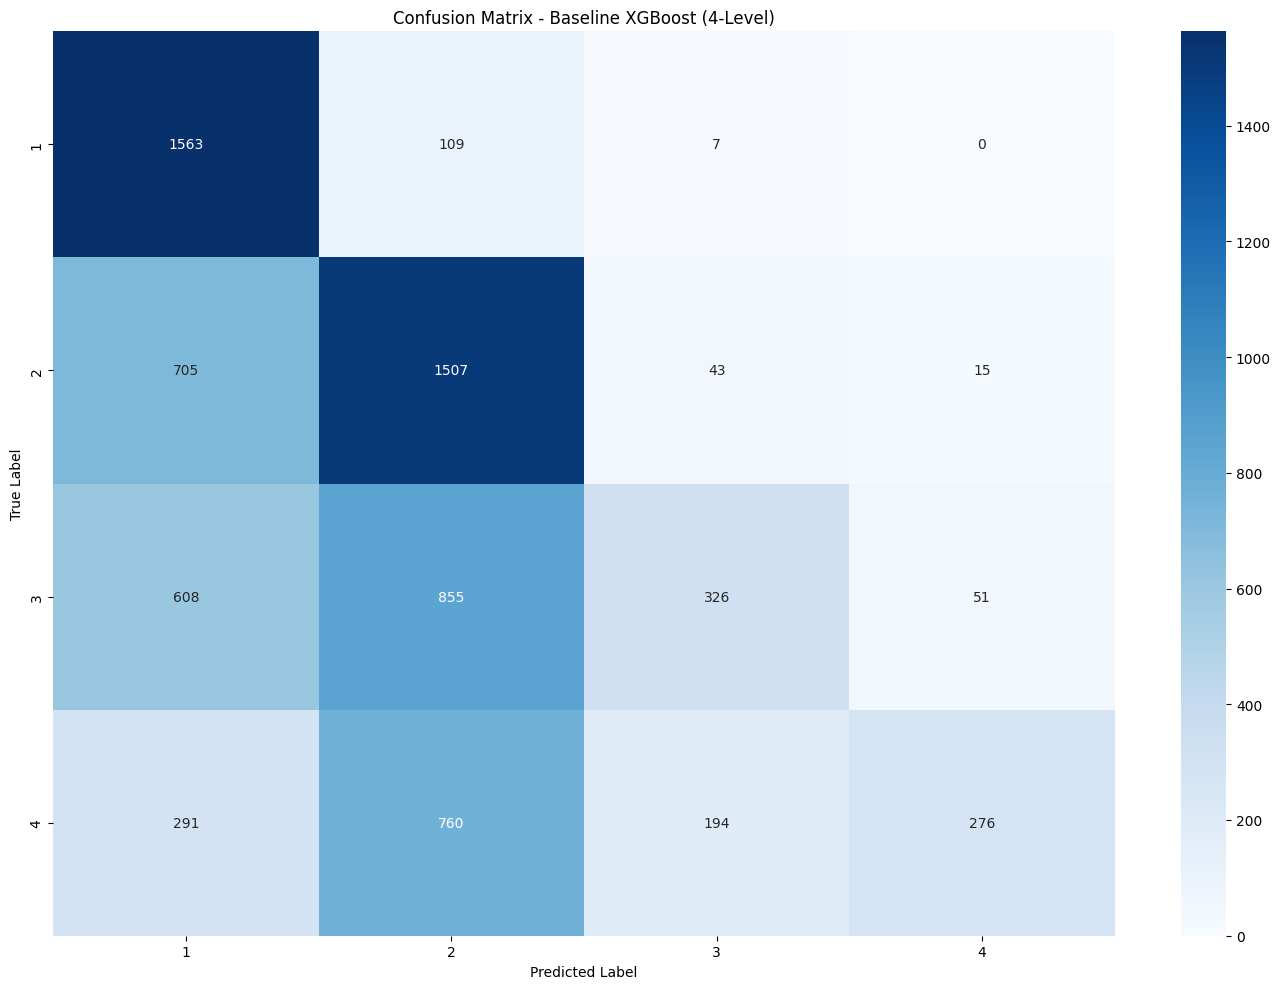

In [18]:
# Define target labels for the separately prepared 4-level classification task
from sklearn.preprocessing import LabelEncoder

xgb_label_encoder_4 = LabelEncoder()
xgb_y_train_4 = xgb_label_encoder_4.fit_transform(xgb_y_train_4_raw)
xgb_y_dev_4 = xgb_label_encoder_4.transform(xgb_y_dev_4_raw)
xgb_y_test_4 = xgb_label_encoder_4.transform(xgb_y_test_4_raw)

print("Encoded four-level classes:", xgb_label_encoder_4.classes_)
print("Encoded label range:", xgb_y_train_4.min(), "to", xgb_y_train_4.max())

from xgboost import XGBClassifier

# Baseline XGBoost model using library default hyperparameters (matches 19-level baseline)
xgb_baseline_4 = XGBClassifier(
    objective="multi:softprob",
    random_state=42
)

print(xgb_baseline_4.get_params())

xgb_baseline_4.fit(
    xgb_X_train_4_tfidf,
    xgb_y_train_4
)

xgb_baseline_4_dev_pred = xgb_baseline_4.predict(xgb_X_dev_4_tfidf)

evaluate_xgb_model(
    xgb_label_encoder_4.inverse_transform(xgb_y_dev_4),
    xgb_label_encoder_4.inverse_transform(xgb_baseline_4_dev_pred),
    "Baseline XGBoost (4-Level) - Dev Set"
)

plot_confusion_matrix(
    xgb_label_encoder_4.inverse_transform(xgb_y_dev_4),
    xgb_label_encoder_4.inverse_transform(xgb_baseline_4_dev_pred),
    labels=list(range(1, 5)),
    title="Confusion Matrix - Baseline XGBoost (4-Level)"
)

### 6.2 XGBoost Baseline Findings (4-Level)

The baseline XGBoost achieved 0.5023 Accuracy, 0.7700 Adjacent Accuracy, and 0.3814 QWK on the development set, with a Macro F1-score of 0.4400.

The confusion matrix shows that the model performs better on Levels 1 and 2, while struggling with higher readability levels. Levels 3 and 4 both achieved a recall of 0.18, with most misclassified samples assigned to Levels 1 or 2.

Overall, the relatively high Adjacent Accuracy indicates that many predictions are within one level of the correct label. However, the low QWK and Macro F1-score indicate limited ordinal agreement and difficulty distinguishing between higher readability levels, despite reducing the task to four classes.

### 6.3 XGBoost Hyperparameter Tuning Using GridSearchCV (4-Level)

`GridSearchCV` selects the `n_estimators` value that produces the **highest Dev QWK**, using a fixed Train/Dev split (`PredefinedSplit`). All candidates are **trained on Train**, evaluated on **Dev**, and **never evaluated on Test** during tuning [5, 6].

**Hyperparameters and Justification**

| Parameter | Setting | Justification |
|---|---|---|
| `n_estimators` | `[100, 200, 300]` (searched) | Tests three tree counts to assess boosting complexity; this is an experimental search range, not a published BAREC optimum [2, 3]. |
| `learning_rate` | `0.3` (fixed) | XGBoost's documented tree-booster default; kept fixed to isolate the effect of tree count [3]. |
| `max_depth` | `6` (fixed) | XGBoost's documented default depth, controlling the complexity of individual trees [3]. |
| Selection metric | **QWK** | Accounts for ordered readability levels and penalizes larger disagreements [1]. |

**Output:** best `n_estimators` and **best Dev QWK**. Class weighting is compared **after** this unweighted search; the chosen tree count is not separately optimized for the balanced variant.


In [19]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import make_scorer, cohen_kappa_score

# Quadratic weighting respects the order of readability levels.
# The 0-based encoded labels preserve the original class spacing.
xgb_qwk_scorer = make_scorer(cohen_kappa_score, weights="quadratic")
from xgboost import XGBClassifier
from scipy.sparse import vstack
import numpy as np

xgb_param_grid_4 = {
    "n_estimators": [100, 200, 300]
}

FIXED_LEARNING_RATE = 0.3   # same fixed value as 19-level, for consistency

# Stack Train and Dev for the fixed CV indices; only Train is fitted per fold
xgb_X_train_dev_4 = vstack([
    xgb_X_train_4_tfidf,
    xgb_X_dev_4_tfidf
])

xgb_y_train_dev_4 = np.concatenate([
    xgb_y_train_4,
    xgb_y_dev_4
])

# Define the fixed split
# -1 = rows used for fitting (Train)
#  0 = rows held out for scoring (Dev)
test_fold_4 = np.concatenate([
    np.full(len(xgb_y_train_4), -1),
    np.zeros(len(xgb_y_dev_4))
])
predefined_split_4 = PredefinedSplit(test_fold=test_fold_4)

# Grid Search uses the same predefined Dev split and QWK scorer
xgb_grid_4 = GridSearchCV(
    estimator=XGBClassifier(
        objective="multi:softprob",
        learning_rate=FIXED_LEARNING_RATE,
        random_state=42,
        max_depth=6,
        tree_method="hist",
        device="cuda"
    ),
    param_grid=xgb_param_grid_4,
    scoring=xgb_qwk_scorer,
    cv=predefined_split_4,
    refit=False,  # keep Dev held out for separate tuned evaluation
    n_jobs=1,
    verbose=2
)

xgb_grid_4.fit(
    xgb_X_train_dev_4,
    xgb_y_train_dev_4
)

print("Best Parameters:", xgb_grid_4.best_params_)
print(f"Best Development QWK: {xgb_grid_4.best_score_:.4f}")

Fitting 1 folds for each of 3 candidates, totalling 3 fits
[CV] END ...................................n_estimators=100; total time= 1.2min
[CV] END ...................................n_estimators=200; total time= 2.0min
[CV] END ...................................n_estimators=300; total time= 2.7min
Best Parameters: {'n_estimators': 300}
Best Development QWK: 0.4194


### 6.4 Tuned XGBoost — Balanced (4-Level)

**Retrain on Train** with GridSearchCV's QWK-selected tree count and balanced `sample_weight` computed from **Train labels only** [7]. Then compute **all metrics and the confusion matrix on Dev**. No Dev samples are used for fitting.


Tuned XGBoost (4-Level) - Balanced - Dev Set
Accuracy:                      0.5161
Adjacent Accuracy (±1):        0.7871
Quadratic Weighted Kappa:      0.4277
Macro F1-score:                0.4697
Weighted Precision:            0.5615
Weighted Recall:               0.5161
Mean Absolute Error (MAE):     0.7413
Root Mean Squared Error:       1.1599
R² Score:                      -0.1995

Classification Report:

              precision    recall  f1-score   support

           1       0.48      0.96      0.64      1679
           2       0.51      0.61      0.56      2270
           3       0.54      0.20      0.29      1840
           4       0.76      0.26      0.39      1521

    accuracy                           0.52      7310
   macro avg       0.57      0.51      0.47      7310
weighted avg       0.56      0.52      0.47      7310



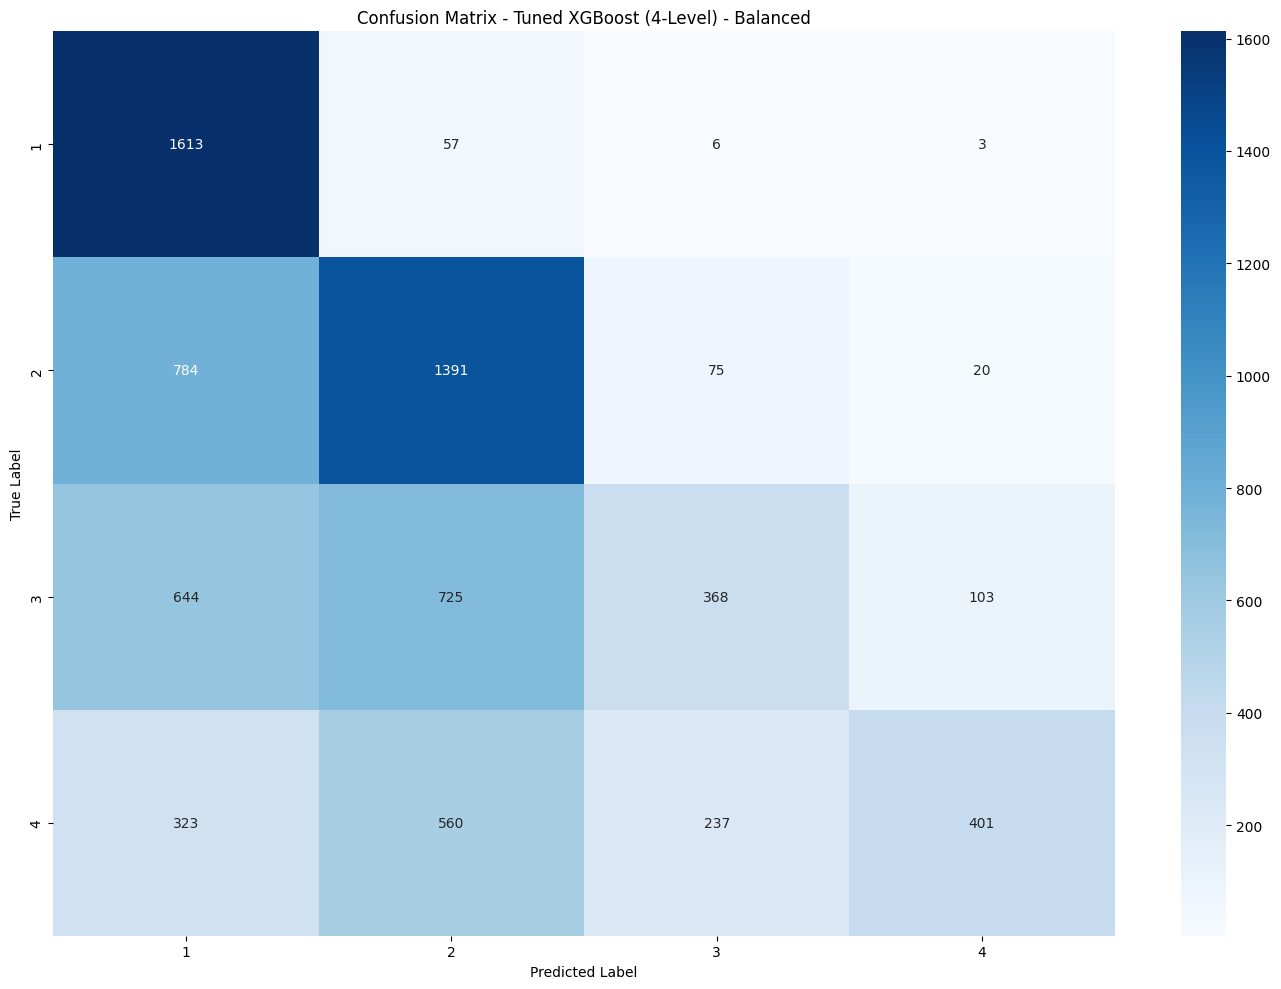

In [20]:
from sklearn.utils.class_weight import compute_sample_weight

xgb_sample_weights_balanced_4 = compute_sample_weight(class_weight="balanced", y=xgb_y_train_4)

# Create tuned XGBoost using the best n_estimators with balanced sample weights
xgb_tuned_4_balanced = XGBClassifier(
    n_estimators=xgb_grid_4.best_params_["n_estimators"],
    learning_rate=FIXED_LEARNING_RATE,
    max_depth=6,
    objective="multi:softprob",
    tree_method="hist",
    device="cuda",
    random_state=42
)

# Fresh fit on Train; evaluate predictions on Dev only
xgb_tuned_4_balanced.fit(
    xgb_X_train_4_tfidf,
    xgb_y_train_4,
    sample_weight=xgb_sample_weights_balanced_4
)

# Predict the held-out Dev set for complete evaluation
xgb_tuned_4_balanced_dev_pred = xgb_tuned_4_balanced.predict(xgb_X_dev_4_tfidf)

evaluate_xgb_model(
    xgb_label_encoder_4.inverse_transform(xgb_y_dev_4),
    xgb_label_encoder_4.inverse_transform(xgb_tuned_4_balanced_dev_pred),
    "Tuned XGBoost (4-Level) - Balanced - Dev Set"
)

plot_confusion_matrix(
    xgb_label_encoder_4.inverse_transform(xgb_y_dev_4),
    xgb_label_encoder_4.inverse_transform(xgb_tuned_4_balanced_dev_pred),
    labels=list(range(1, 5)),
    title="Confusion Matrix - Tuned XGBoost (4-Level) - Balanced"
)

### 6.5 Tuned XGBoost — No Class Weighting (4-Level)

**Retrain on Train** using the same QWK-selected hyperparameters but without sample weights. Evaluate **all metrics and the confusion matrix on Dev**. This comparison isolates the effect of class balancing at a fixed tree count.


Tuned XGBoost (4-Level) - None - Dev Set
Accuracy:                      0.5233
Adjacent Accuracy (±1):        0.7885
Quadratic Weighted Kappa:      0.4194
Macro F1-score:                0.4690
Weighted Precision:            0.5777
Weighted Recall:               0.5233
Mean Absolute Error (MAE):     0.7239
Root Mean Squared Error:       1.1357
R² Score:                      -0.1498

Classification Report:

              precision    recall  f1-score   support

           1       0.52      0.93      0.66      1679
           2       0.48      0.69      0.57      2270
           3       0.57      0.21      0.30      1840
           4       0.80      0.22      0.34      1521

    accuracy                           0.52      7310
   macro avg       0.59      0.51      0.47      7310
weighted avg       0.58      0.52      0.48      7310



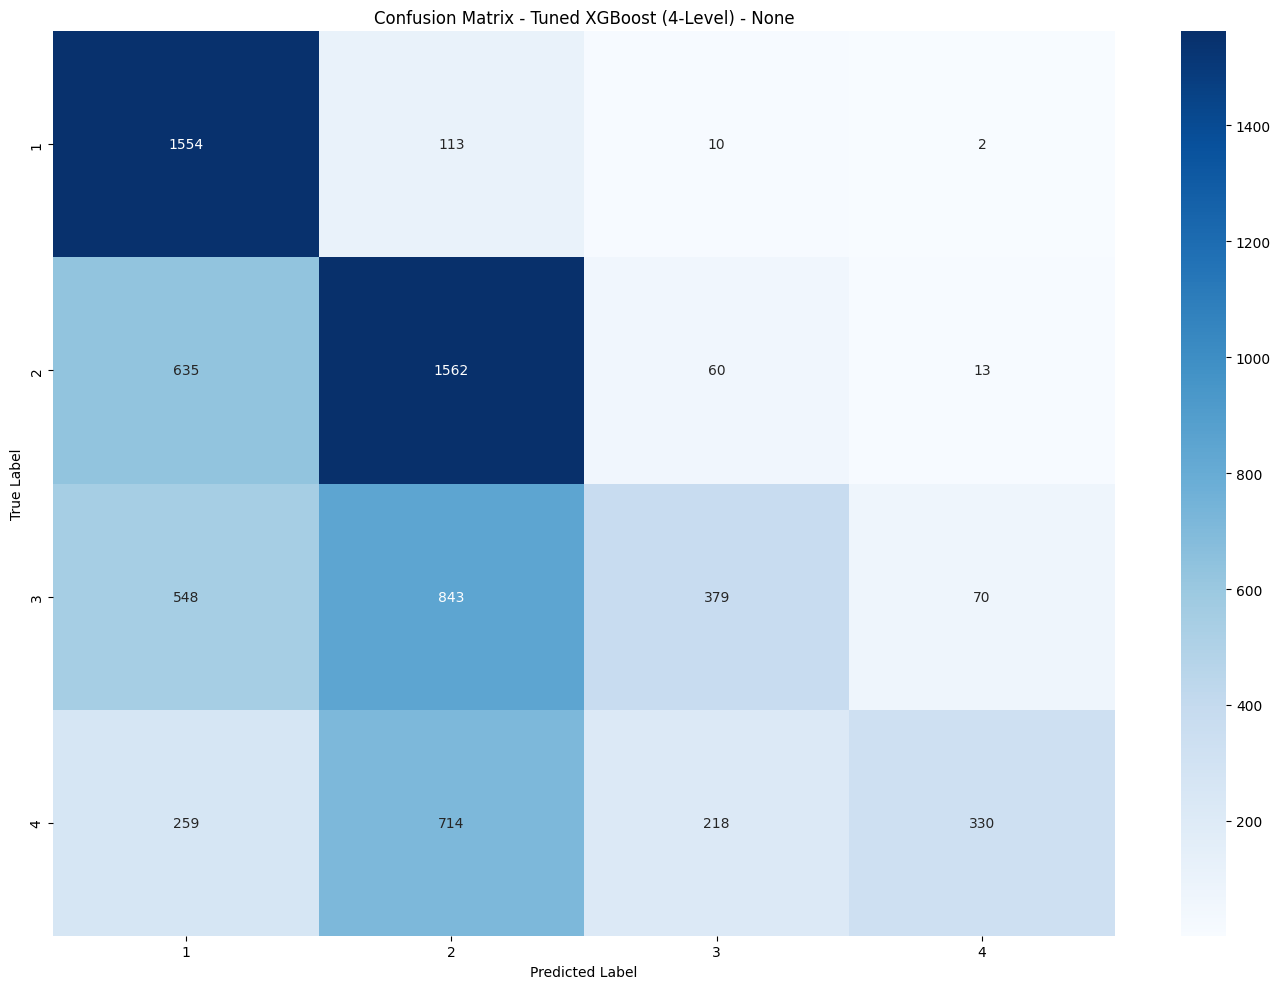

In [21]:
# Use the n_estimators value selected by Dev QWK (without weighting)
xgb_tuned_4_none = XGBClassifier(
    n_estimators=xgb_grid_4.best_params_["n_estimators"],
    learning_rate=FIXED_LEARNING_RATE,
    max_depth=6,
    objective="multi:softprob",
    tree_method="hist",
    device="cuda",
    random_state=42
)

# Fresh fit on Train; evaluate predictions on Dev only
xgb_tuned_4_none.fit(
    xgb_X_train_4_tfidf,
    xgb_y_train_4
)

# Predict the held-out Dev set for complete evaluation
xgb_tuned_4_none_dev_pred = xgb_tuned_4_none.predict(xgb_X_dev_4_tfidf)

evaluate_xgb_model(
    xgb_label_encoder_4.inverse_transform(xgb_y_dev_4),
    xgb_label_encoder_4.inverse_transform(xgb_tuned_4_none_dev_pred),
    "Tuned XGBoost (4-Level) - None - Dev Set"
)

plot_confusion_matrix(
    xgb_label_encoder_4.inverse_transform(xgb_y_dev_4),
    xgb_label_encoder_4.inverse_transform(xgb_tuned_4_none_dev_pred),
    labels=list(range(1, 5)),
    title="Confusion Matrix - Tuned XGBoost (4-Level) - None"
)

### 6.6 Tuned XGBoost Findings (4-Level)

GridSearchCV selected n_estimators = 300, achieving a best Dev QWK of 0.4194.

The tuned unbalanced model achieved the highest Accuracy (0.5233), Adjacent Accuracy (0.7885), and lowest MAE (0.7239). The balanced model achieved slightly higher QWK (0.4277 vs. 0.4194) and Macro F1-score (0.4697 vs. 0.4690).

The confusion matrices show that balancing improved Level 4 recall from 0.22 to 0.26, while Level 3 recall remained low for both configurations.

Overall, tuning improved the baseline results, while class balancing provided a small improvement in ordinal agreement at the cost of slightly lower Accuracy and higher prediction errors.



# 7. Final XGBoost Experimental Comparison

## 7.1 Overall Performance Comparison

The baseline and tuned XGBoost models were evaluated on the development set across the 19-level, 5-level, and 4-level classification tasks. Hyperparameter tuning was performed using **QWK** as the selection criterion.

| Classification Level | Model | Accuracy | Adjacent Accuracy (±1) | QWK | Macro F1 | Weighted Precision | Weighted Recall | MAE | RMSE | R² |
|---|---|---|---|---|---|---|---|---|---|---|
| 19-Level | Baseline | 0.3372 | 0.4360 | 0.2988 | 0.2341 | 0.3827 | 0.3372 | 2.4997 | 3.6366 | -0.1634 |
| 19-Level | Tuned - Balanced | 0.2996 | 0.4126 | 0.4285 | 0.2350 | 0.3800 | 0.2996 | 2.8337 | 4.0697 | -0.4570 |
| 19-Level | Tuned - None | 0.3543 | 0.4592 | 0.3665 | 0.2446 | 0.3767 | 0.3543 | 2.4124 | 3.5772 | -0.1257 |
| 5-Level | Baseline | 0.4975 | 0.7673 | 0.3637 | 0.3526 | 0.5394 | 0.4975 | 0.7952 | 1.2310 | -0.2332 |
| 5-Level | Tuned - Balanced | 0.5057 | 0.7791 | 0.4174 | 0.3904 | 0.5344 | 0.5057 | 0.7795 | 1.2229 | -0.2171 |
| 5-Level | Tuned - None | 0.5160 | 0.7858 | 0.3994 | 0.3740 | 0.5418 | 0.5160 | 0.7536 | 1.1909 | -0.1542 |
| 4-Level | Baseline | 0.5023 | 0.7700 | 0.3814 | 0.4400 | 0.5701 | 0.5023 | 0.7674 | 1.1775 | -0.2362 |
| 4-Level | Tuned - Balanced | 0.5161 | 0.7871 | 0.4277 | 0.4697 | 0.5615 | 0.5161 | 0.7413 | 1.1599 | -0.1995 |
| 4-Level | Tuned - None | 0.5233 | 0.7885 | 0.4194 | 0.4690 | 0.5777 | 0.5233 | 0.7239 | 1.1357 | -0.1498 |

## 7.2 Hyperparameter Tuning Results

GridSearchCV selected the following hyperparameters using development-set **QWK**:

| Classification Level | Best n_estimators | Best Dev QWK |
|---|---|---|
| 19-Level | 300 | 0.3665 |
| 5-Level | 300 | 0.3994 |
| 4-Level | 300 | 0.4194 |

All three tasks selected **300 trees**, the highest value in the search space `[100, 200, 300]`. This was the best-performing configuration among the tested values, although larger tree counts were not evaluated.

The reported GridSearchCV scores correspond to the unbalanced search. The balanced models were separately retrained using the selected parameters.

## 7.3 Analysis of Experimental Results

The results show that reducing the number of readability levels generally improved Accuracy and Macro F1-score. The highest exact classification Accuracy was achieved by the **tuned unbalanced 4-level model (0.5233)**.

QWK-based hyperparameter tuning improved the unbalanced models' performance over their baselines across all three tasks. Class balancing further increased QWK, particularly in the 19-level task, where it improved from 0.2988 at baseline to 0.4285.

However, the balanced models consistently achieved lower Accuracy and higher MAE than their tuned unbalanced counterparts. This indicates a trade-off between chance-adjusted ordinal agreement and prediction accuracy.

The confusion matrices also revealed persistent difficulties in recognizing higher readability levels, despite the improvements achieved through tuning and class balancing.

## 7.4 Conclusion

The XGBoost experiments demonstrate that hyperparameter tuning improves model performance, while class balancing produces higher QWK scores across all three classification tasks.

The tuned unbalanced models achieved the strongest Accuracy and lowest MAE within each task. In contrast, the balanced models achieved better ordinal agreement, although their prediction errors were generally higher.

**For Arabic readability classification, QWK is particularly important because readability levels are ordered.** However, the improvements in QWK must be considered alongside Accuracy, Macro F1-score, and MAE to avoid overlooking large prediction errors.

Overall, the tuned balanced models offer stronger QWK performance, while the tuned unbalanced models provide more accurate predictions. The final selection should be based on the project's evaluation priorities, followed by an independent assessment on the Test set.


## **8. References**

[1] K. N. Elmadani, N. Habash, and H. Taha-Thomure, “A Large and Balanced Corpus for Fine-grained Arabic Readability Assessment,” *Findings of ACL*, pp. 16376–16400, 2025. https://aclanthology.org/2025.findings-acl.842/

[2] T. Chen and C. Guestrin, “XGBoost: A Scalable Tree Boosting System,” *Proceedings of KDD*, pp. 785–794, 2016. https://doi.org/10.1145/2939672.2939785

[3] XGBoost Developers, “XGBoost Parameters,” *Official Documentation*. https://xgboost.readthedocs.io/en/stable/parameter.html

[4] scikit-learn Developers, “TfidfVectorizer,” *scikit-learn Documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html

[5] scikit-learn Developers, “GridSearchCV,” *scikit-learn Documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

[6] scikit-learn Developers, “PredefinedSplit,” *scikit-learn Documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.PredefinedSplit.html

[7] scikit-learn Developers, “compute_sample_weight,” *scikit-learn Documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_sample_weight.html

[8] S. Alzubi and R. Reynolds, “Transformer-based Readability Classifiers Are Worse Than You Think: Evidence from Cross-Domain Arabic Readability Assessment,” *Proceedings of BEA*, pp. 766–776, 2026. https://aclanthology.org/2026.bea-1.52/

[9] B. W. Lee, Y. S. Jang, and J. Lee, “Pushing on Text Readability Assessment: A Transformer Meets Handcrafted Linguistic Features,” *Proceedings of EMNLP*, pp. 10669–10686, 2021. https://aclanthology.org/2021.emnlp-main.834/

**Reference scope:** [8] supports the *relevance of XGBoost to Arabic readability* and its use of tree depth 6, **not** this notebook's specific 100–300 tree grid, 0.3 learning rate, or TF-IDF features. [9] is related readability research, not evidence for the selected XGBoost hyperparameter values.